# EO4FLOOD soil moisture

Satellite surface soil moisture describes antecedent catchment conditions: the same storm can run
off a saturated catchment and soak into a dry one. This Ebro demonstration examines SMAP quality
flags and sampling, long-term spatial statistics, soil wetness around the December 2021 event,
seasonal behaviour, and the timing seen by SMAP, ASCAT and SMOS. Each product is read directly
from the public Zarr asset recorded in its STAC item.

SMAP is a NASA L-band radiometer product, regridded onto the SMOS grid. The grid centres are about
0.26 degrees apart, with latitude spacing that is not perfectly uniform.

| Variable | Dimensions | Meaning |
|---|---|---|
| `soil_moisture` | `(time, lat, lon)` | SMAP volumetric surface soil moisture, m³/m³ |
| `error` | `(time, lat, lon)` | Retrieval uncertainty, m³/m³ |
| `quality_flag` | `(time, lat, lon)` | SMAP retrieval-quality bits; zero denotes recommended quality |
| `time` | `(time)` | Overpass timestamp |
| `lat`, `lon` | `(lat)`, `(lon)` | Cell centres in geographic degrees |

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import s3fs
from urllib.parse import urlparse
import matplotlib.pyplot as plt

s3 = s3fs.S3FileSystem(anon=True, client_kwargs={
    "endpoint_url": "https://s3.waw4-1.cloudferro.com"
})

PRODUCT_URLS = {
    "SMAP": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/soil_moisture_zarr/EO4FLOOD_soil_moisture_SMAP_ebro.zarr",
    "ASCAT": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/soil_moisture_zarr/EO4FLOOD_soil_moisture_ASCAT_ebro.zarr",
    "SMOS": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/soil_moisture_zarr/EO4FLOOD_soil_moisture_SMOS_ebro.zarr"
}
BASIN = "Ebro"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})

START, END = "2016-01-01", "2024-12-31"
EVENT_START, EVENT_END = "2021-12-05", "2021-12-15"
MAP_DAY = "2021-12-10"
POINT_LAT, POINT_LON = 41.65, -0.88
MIN_COVERAGE = 0.5
url = PRODUCT_URLS["SMAP"]
ds = xr.open_zarr(s3.get_mapper(urlparse(url).path.lstrip("/")), consolidated=False, chunks=None).load()
ds

<xarray.Dataset> Size: 28MB
Dimensions:        (time: 6414, lat: 11, lon: 25)
Coordinates:
  * time           (time) datetime64[ns] 51kB 2016-01-01T01:18:09.848999936 ....
  * lat            (lat) float32 44B 40.36 40.62 40.87 ... 42.44 42.7 42.97
  * lon            (lon) float32 100B -4.28 -4.02 -3.761 ... 1.427 1.686 1.945
Data variables:
    error          (time, lat, lon) float32 7MB nan nan nan nan ... nan nan nan
    quality_flag   (time, lat, lon) float64 14MB 1.0 5.0 5.0 5.0 ... 7.0 7.0 7.0
    soil_moisture  (time, lat, lon) float32 7MB 0.2568 0.4885 0.4885 ... nan nan
Attributes: (12/13)
    title:                       ESA EO4FLOOD project Soil Moisture input
    creation_time:               2025-07-24 18:19:03 UTC
    institution:                 National Research Council (CNR)
    creator_institution_e-mail:  christian.massari@cnr.it
    references:                  To be filled with EO4FLOOD publication DOI o...
    Temporal interval:           From 2016-01-01 to NaT
    ...                          ...
    Conventions:                 CF-1.11-draft
    DOI:                         https://doi.org/xxx.xxxx
    Acknowledgements:            ESA EO4FLOOD project reference
    history:                     Regridded SMAP file onto SMOS grid using xES...
    source:                      SMAP Level 3 product (regridded)
    note:                        SMOS-specific metadata removed; grid info re...

## Overpasses, gaps and grid support

There is one value per overpass, not one value per day. Daily fields average the available overpasses;
a day with no retrieval remains empty. Each overpass sees only part of the domain, so the spatial
mean is retained only when at least 50% of the potentially observed cells have a value that day.

The grid is finer than the sensor. SMAP's approximately 36 km retrievals were regridded by nearest
neighbour onto an approximately 25 km grid, so neighbouring cells can carry the same series. The
delivery notes report 119 distinct series among 257 Ebro land cells; the grid does not provide 257
independent observations.

The delivered SMAP Ebro record includes 734 undated overpasses at the end of the time axis. They
cannot be placed in time and are excluded. The delivery notes also identify an empty `error` variable.
Overpass times fall around 00–02 UTC; their precise interpretation is not established by the metadata.

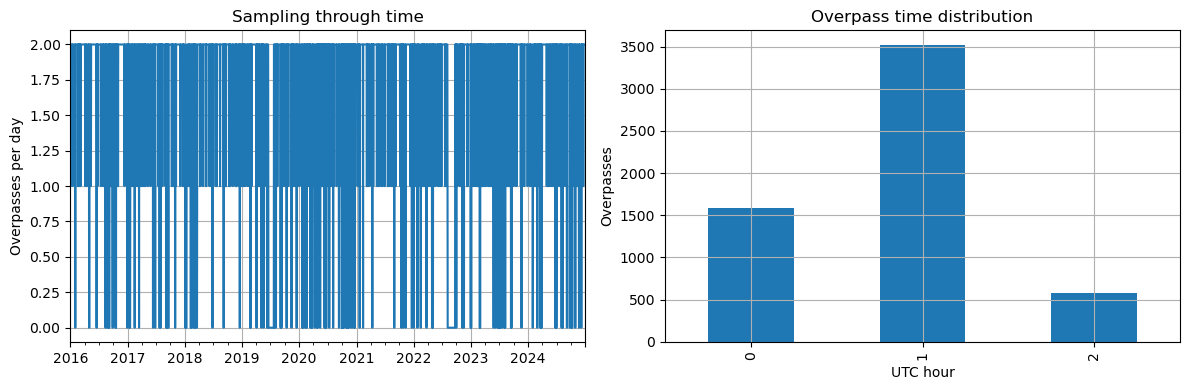

In [2]:
valid_times = ds.time.values[ds.time.notnull().values]
overpasses = pd.Series(1, index=pd.DatetimeIndex(valid_times))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
overpasses.resample("1D").sum().plot(ax=axes[0], ylabel="Overpasses per day", title="Sampling through time")
pd.Series(pd.DatetimeIndex(valid_times).hour).value_counts().sort_index().plot.bar(
    ax=axes[1], xlabel="UTC hour", ylabel="Overpasses", title="Overpass time distribution")
fig.tight_layout()
plt.show()

## SMAP quality flags and observed coverage

The quality flag follows the SMAP Level 3 convention: a set bit records a condition that was not met.

- Bit 0: recommended quality was not achieved.
- Bit 1: retrieval was not attempted.
- Bit 2: retrieval was unsuccessful.
- Bit 3: its interpretation varies between SMAP versions; the delivery does not resolve which applies.

A value of zero denotes recommended quality; one denotes a retrieval that is not recommended, and
seven has bits 0–2 set. This analysis keeps `quality_flag == 0`. The quality table counts all flag
values, while the map shows where filtering removes retrievals and the time series shows daily coverage.

The quality choice affects spatial support as well as noise. The delivery notes report that filtering
Ebro SMAP removes about 35% of retrievals, concentrated partly in wetter terrain. A mean based on a
smaller observed area should not be interpreted as a uniform measurement of the entire catchment.

Overpasses without timestamps: 734


,Domain mean,Point
count,1323.000000,0.0
mean,0.167985,NaN
std,0.049554,NaN
min,0.083802,NaN
25%,0.122151,NaN
50%,0.165153,NaN
75%,0.207784,NaN
max,0.301560,NaN


,quality_flag,retrievals
0,0,461808
1,1,208130
2,5,27551
3,7,793644
4,8,3072
5,9,16860
6,13,281
7,15,50654


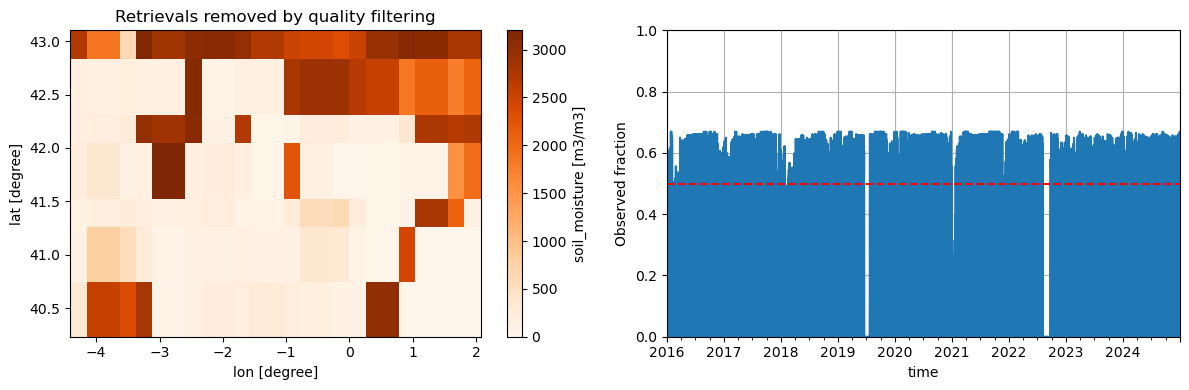

In [3]:
print("Overpasses without timestamps:", int(ds.time.isnull().sum()))
ds = ds.sel(time=ds.time.notnull()).sortby("time").sel(time=slice(START, END))
raw = ds.soil_moisture
sm = raw.where(ds.quality_flag == 0)
daily = sm.resample(time="1D").mean()
footprint = raw.notnull().any("time")
coverage = daily.notnull().sum(["lat", "lon"]) / footprint.sum()
area = daily.mean(["lat", "lon"]).where(coverage >= MIN_COVERAGE).to_series()
point = daily.sel(lat=POINT_LAT, lon=POINT_LON, method="nearest").to_series()
series = pd.DataFrame({"Domain mean": area, "Point": point})
display(series.describe())
flags, counts = np.unique(ds.quality_flag.values[np.isfinite(ds.quality_flag.values)], return_counts=True)
display(pd.DataFrame({"quality_flag": flags.astype(int), "retrievals": counts}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(raw.notnull().sum("time") - sm.notnull().sum("time")).plot(ax=axes[0], cmap="Oranges")
axes[0].set_title("Retrievals removed by quality filtering")
coverage.to_series().plot(ax=axes[1], ylim=(0, 1), ylabel="Observed fraction")
axes[1].axhline(MIN_COVERAGE, color="red", linestyle="--")
fig.tight_layout()
plt.show()

## Whole-record soil moisture statistics

The mean map describes the soil's usual state. The 5th and 95th percentiles bracket dry and wet
conditions; the standard deviation shows where conditions fluctuate. Their spatial pattern helps
identify where antecedent wetness can modulate runoff. These statistics describe available,
quality-filtered observations, so the sampling and coverage plots are important context.

/home/krasen/test/earthcode-library/.pixi/envs/default/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


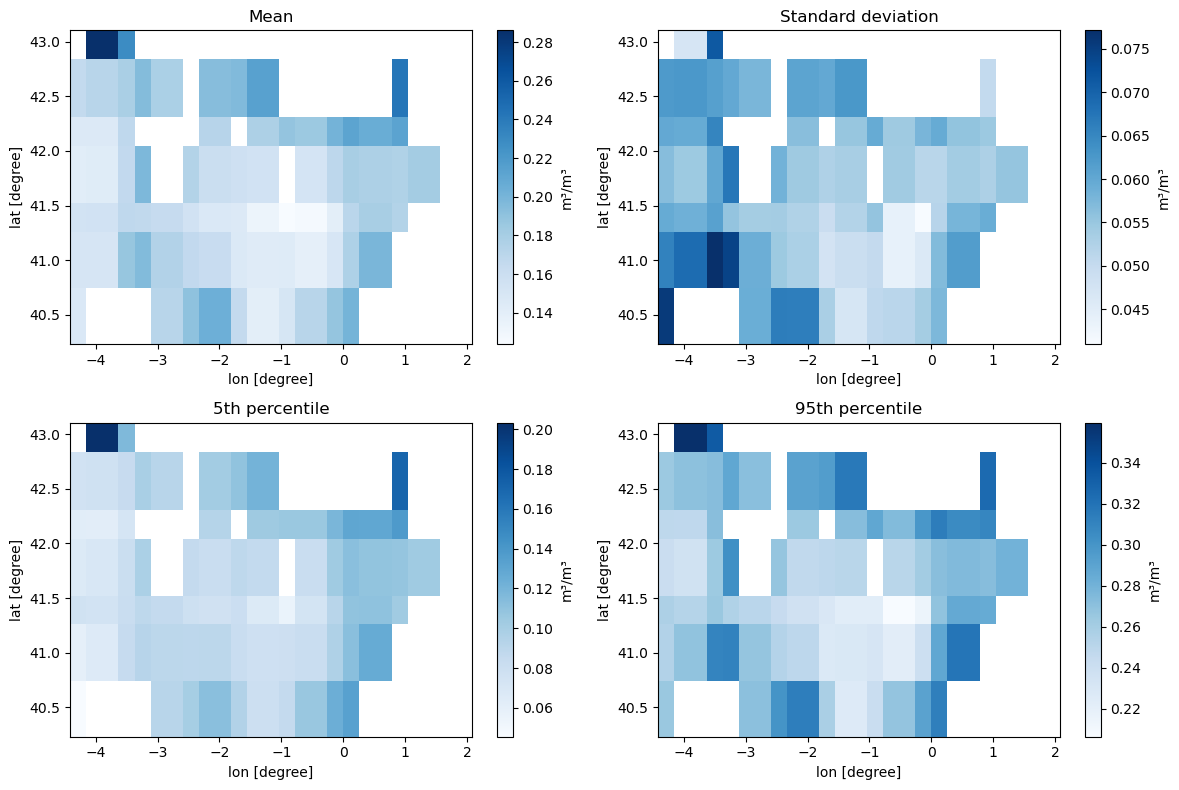

In [4]:
fields = [daily.mean("time"), daily.std("time"),
          daily.quantile(0.05, dim="time"), daily.quantile(0.95, dim="time")]
titles = ["Mean", "Standard deviation", "5th percentile", "95th percentile"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for field, title, ax in zip(fields, titles, axes.flat):
    field.plot(ax=ax, cmap="Blues", cbar_kwargs={"label": "m³/m³"})
    ax.set_title(title)
fig.tight_layout()
plt.show()

## Antecedent conditions around the December 2021 event

For a flood, the state of the soil before the rain matters. The event mean for 5–15 December 2021
is compared with the preceding seven days. Their difference describes the change in wetness;
the single-day panel gives the daily field for 10 December. Missing observations remain blank.

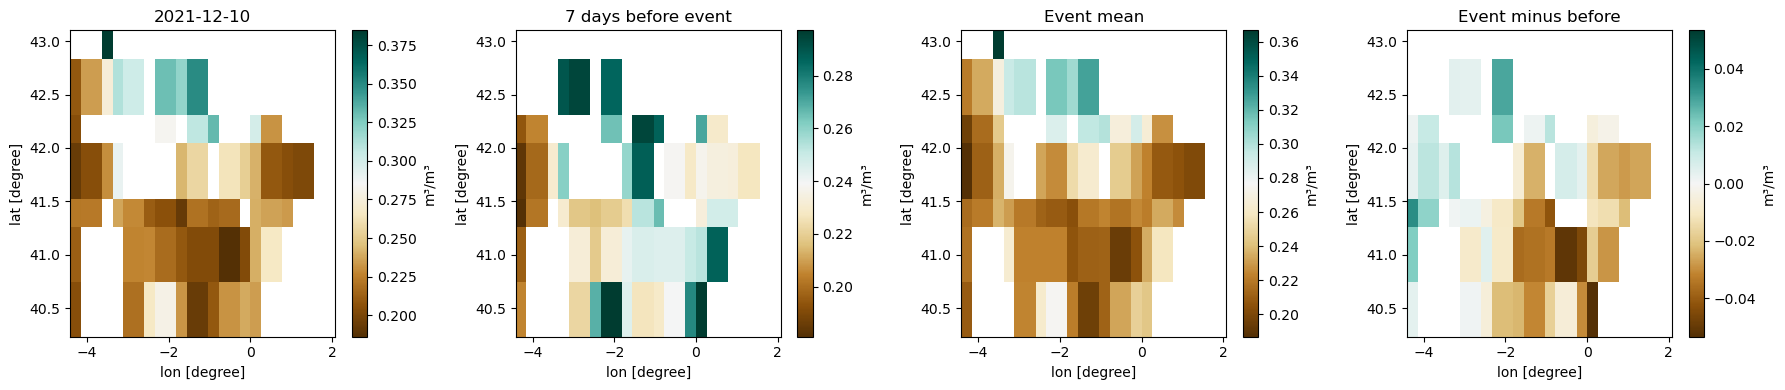

In [5]:
event = daily.sel(time=slice(EVENT_START, EVENT_END)).mean("time")
pre_event = daily.sel(time=slice(pd.Timestamp(EVENT_START) - pd.Timedelta(days=7),
                                pd.Timestamp(EVENT_START) - pd.Timedelta(days=1))).mean("time")
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for field, title, ax in zip(
    [daily.sel(time=MAP_DAY), pre_event, event, event - pre_event],
    [MAP_DAY, "7 days before event", "Event mean", "Event minus before"], axes
):
    field.plot(ax=ax, cmap="BrBG", cbar_kwargs={"label": "m³/m³"})
    ax.set_title(title)
fig.tight_layout()
plt.show()

## Time series, seasonal cycle and anomalies

The spatial mean and the point near Zaragoza show wetting and drying at different spatial supports.
Monthly climatology answers when the soil is usually wet. The anomaly shown here is the departure
from this record's day-of-year mean, expressed in m³/m³; it describes this nine-year record rather
than a long-term climatological normal.

Annual means and maps summarise year-to-year variation, but years with different observation
coverage are not directly comparable. Longer gaps in the delivered SMAP series, including mid-2019
and late summer 2022, may reflect spacecraft outages; that attribution is not established by the data alone.

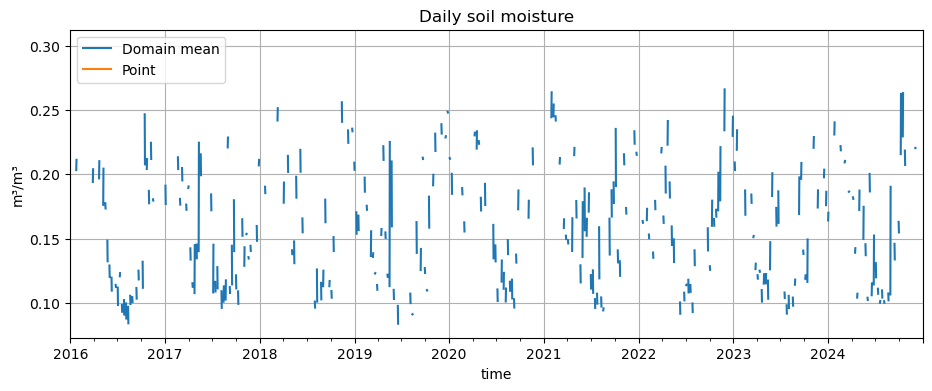

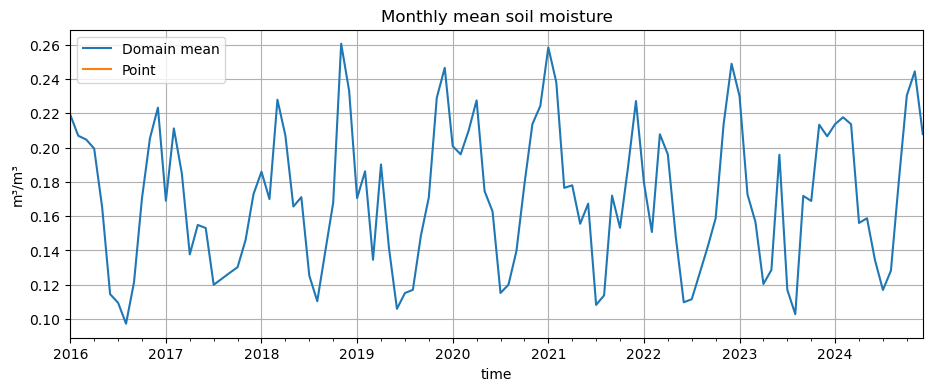

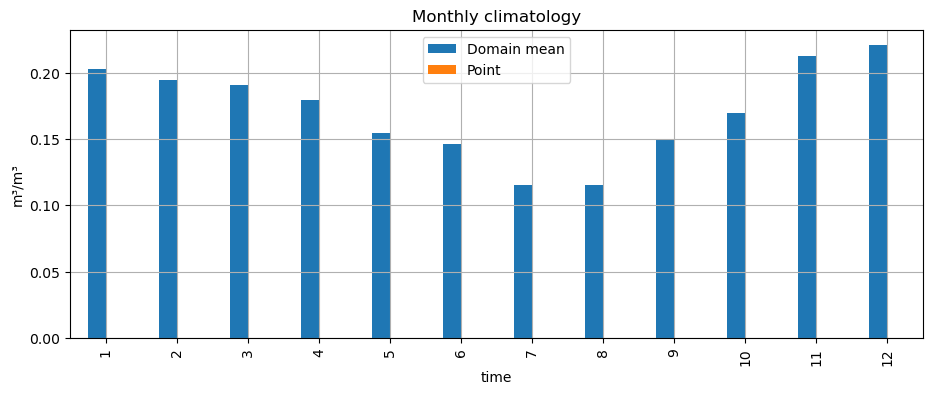

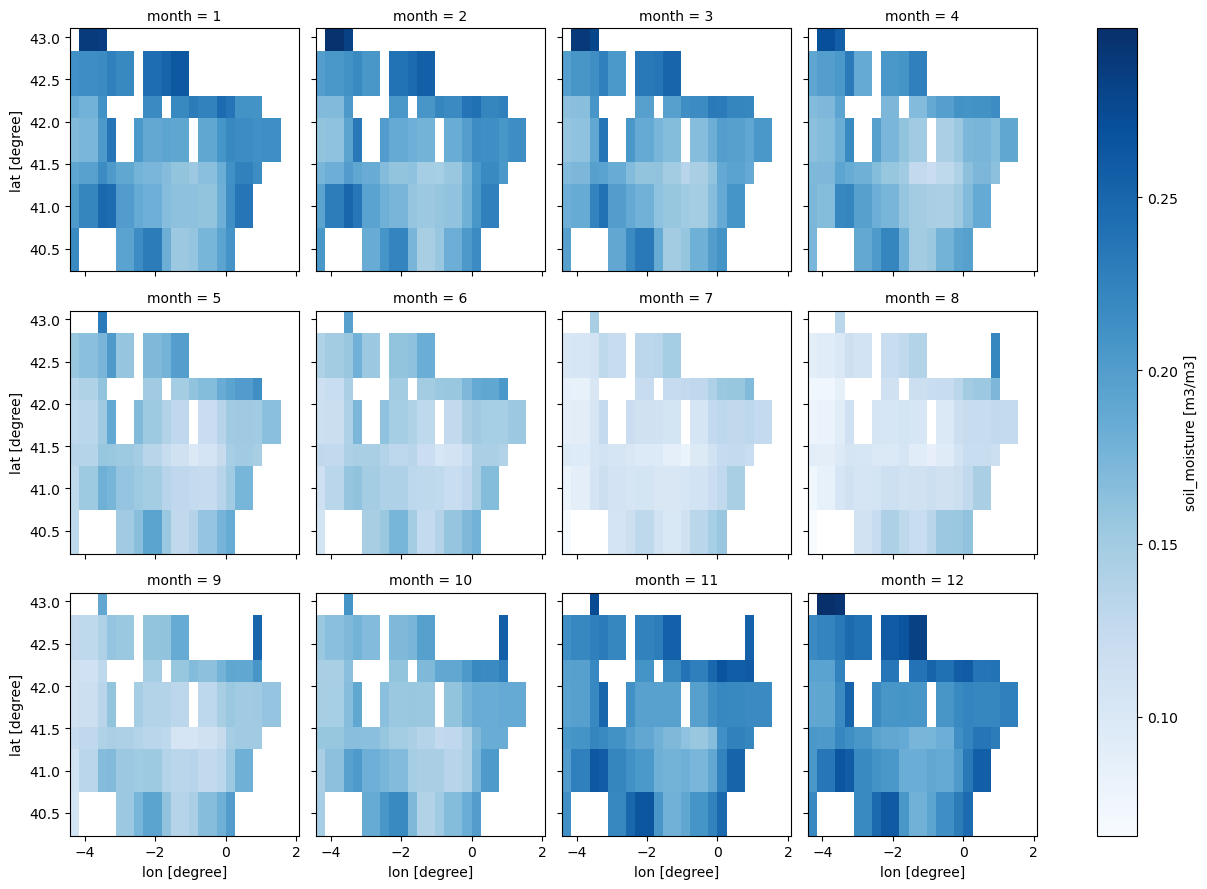

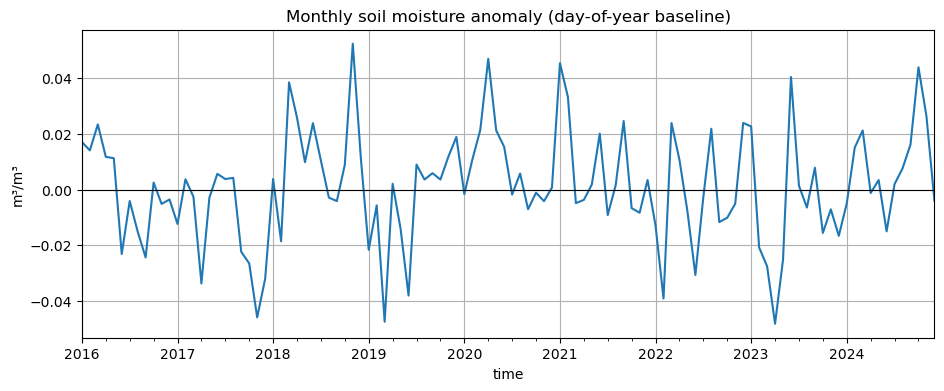

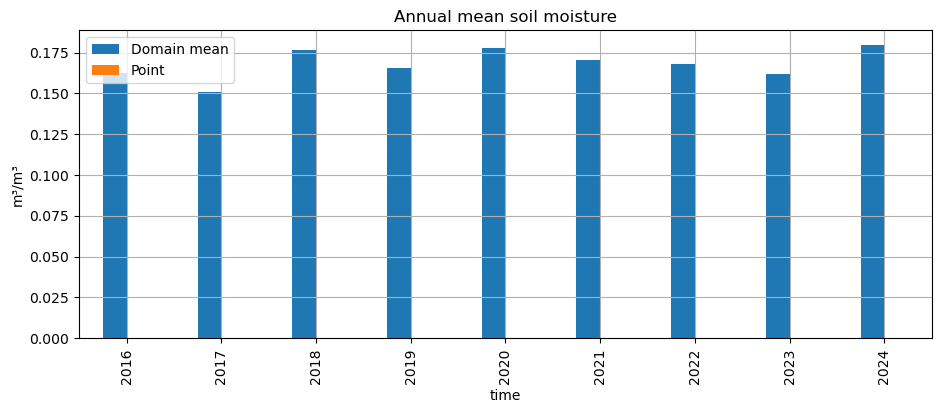

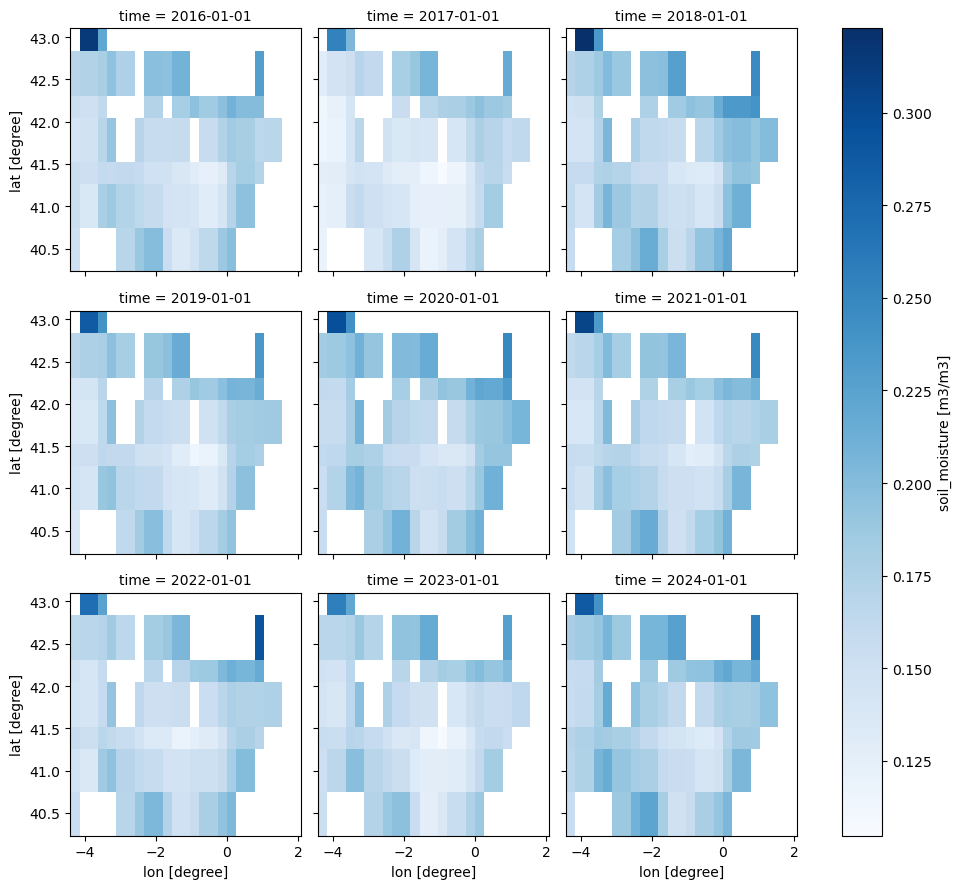

In [6]:
series.plot(ylabel="m³/m³", title="Daily soil moisture")
plt.show()
monthly = series.resample("MS").mean()
monthly.plot(ylabel="m³/m³", title="Monthly mean soil moisture")
plt.show()
climatology = monthly.groupby(monthly.index.month).mean()
climatology.plot.bar(ylabel="m³/m³", title="Monthly climatology")
plt.show()
monthly_maps = daily.resample(time="MS").mean().groupby("time.month").mean("time")
monthly_maps.plot(col="month", col_wrap=4, cmap="Blues")
plt.show()
anomaly = area - area.groupby(area.index.dayofyear).transform("mean")
anomaly.resample("MS").mean().plot(ylabel="m³/m³", title="Monthly soil moisture anomaly (day-of-year baseline)")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()
annual = series.resample("YS").mean()
annual.index = annual.index.year
annual.plot.bar(ylabel="m³/m³", title="Annual mean soil moisture")
plt.show()
daily.resample(time="YS").mean().plot(col="time", col_wrap=3, cmap="Blues")
plt.show()

## SMAP, ASCAT and SMOS

Different satellites see the soil in different ways. L-band radiometers such as SMAP and SMOS sense
near-surface moisture, while C-band scatterometry from ASCAT is related to relative saturation.
Comparing their timing and anomalies is therefore more direct than treating all absolute values
as interchangeable volumetric measurements. The ASCAT delivery does not supply a units attribute.

SMAP uses recommended-quality retrievals here. ASCAT and SMOS use the delivered values, each with
its own observed footprint and the same 50% daily-coverage threshold. The comparison shows monthly
series and correlations; differences include spatial support and quality treatment as well as sensor behaviour.

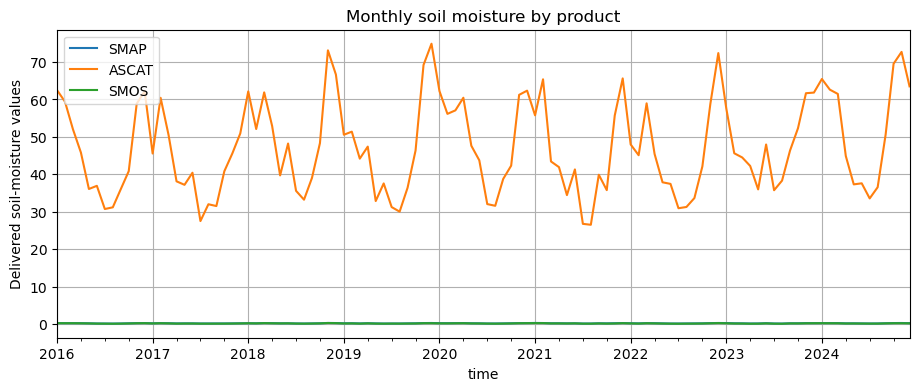

,SMAP,ASCAT,SMOS
SMAP,1.000000,0.878468,0.848488
ASCAT,0.878468,1.000000,0.785972
SMOS,0.848488,0.785972,1.000000


In [7]:
with xr.open_zarr(s3.get_mapper(urlparse(PRODUCT_URLS["ASCAT"]).path.lstrip("/")), consolidated=False, chunks=None) as source:
    ascat = source.soil_moisture.sortby("time").sel(time=slice(START, END)).load()
with xr.open_zarr(s3.get_mapper(urlparse(PRODUCT_URLS["SMOS"]).path.lstrip("/")), consolidated=False, chunks=None) as source:
    smos = source.Soil_Moisture.sortby("time").sel(time=slice(START, END)).load()
comparison = {"SMAP": area}
for product, values in [("ASCAT", ascat), ("SMOS", smos)]:
    day = values.resample(time="1D").mean()
    fraction = day.notnull().sum(["lat", "lon"]) / values.notnull().any("time").sum()
    comparison[product] = day.mean(["lat", "lon"]).where(fraction >= MIN_COVERAGE).to_series()
compare = pd.DataFrame(comparison)
compare.resample("MS").mean().plot(ylabel="Delivered soil-moisture values", title="Monthly soil moisture by product")
plt.show()
display(compare.corr())


ds.close()